# 5 MWp Solar PV Plant — Python Design & Simulation
**Author:** Maduakor Uchechukwu David · MSc Energy for Solar Buildings and Cities

This notebook re-builds my 5 MWp Montpellier plant design in Python, step by step:

| # | Section | What it shows |
|---|---|---|
| 1 | Solar resource | Hourly weather from PVGIS, monthly irradiation, a day × hour heatmap |
| 2 | String sizing | Cold-weather Voc, hot Vmp and MPPT current checked against the inverter datasheet |
| 3 | Plane-of-array & cell temperature | Transposition to a 35° south-facing plane, SAPM cell temperature |
| 4 | Energy simulation | PVWatts DC + inverter model with clipping, monthly energy, PR, comparison with PVGIS |
| 5 | DC/AC ratio study | Energy gained vs clipping lost as the DC/AC ratio changes |
| 6 | Tilt & azimuth study | Annual in-plane irradiation for every tilt/azimuth pair |



**Libraries:** `pvlib`, `pandas`, `numpy`, `matplotlib`.  Install once with `pip install pvlib pandas matplotlib`.

In [1]:
%pip install pvlib scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from pathlib import Path

plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "font.size": 10,
})
BLUE, ORANGE, GREY = "#2F6FB3", "#C2410C", "#8A8A8A"

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
print("pvlib", pvlib.__version__, "| pandas", pd.__version__)

pvlib 0.16.1 | pandas 2.2.3


**Libraries used**
- `pvlib`: downloads PVGIS weather and models solar position, irradiance and PV output
- `pandas`: stores the 8,760 hourly values in a table (DataFrame) with a time index
- `numpy`: fast maths on arrays (pandas is built on it)
- `matplotlib.pyplot`: plots and charts

## 1. Solar resource — Montpellier, France
PVGIS gives a **Typical Meteorological Year (TMY)**: 8,760 hourly values of irradiance (GHI, DNI, DHI), air temperature and wind speed.
Each month is picked as the most "typical" month from many real years of satellite data.
`pvlib.iotools.get_pvgis_tmy` downloads it directly. Timestamps are in **UTC**, and the year 1990 is only a placeholder.

In [3]:
weather,meta = pvlib.iotools.get_pvgis_tmy(latitude=43.611, longitude=3.877, map_variables=True)
weather.head()

,temp_air,relative_humidity,ghi,dni,dhi,IR(h),wind_speed,wind_direction,pressure
time(UTC),,,,,,,,,
1990-01-01 00:00:00+00:00,13.23,78.47,0.0,0.0,0.0,330.12,4.84,286.0,101500.0
1990-01-01 01:00:00+00:00,13.13,79.13,0.0,0.0,0.0,329.50,4.73,288.0,101480.0
1990-01-01 02:00:00+00:00,13.03,79.80,0.0,0.0,0.0,328.87,4.61,290.0,101500.0
1990-01-01 03:00:00+00:00,12.93,80.46,0.0,0.0,0.0,328.24,4.50,289.0,101490.0
1990-01-01 04:00:00+00:00,12.83,81.13,0.0,0.0,0.0,327.62,4.39,288.0,101480.0


In [4]:
# Statistics for the 5 key weather variables (real PVGIS TMY data)
cols = ["ghi", "dni", "dhi", "temp_air", "wind_speed"]

stats = weather[cols].describe().round(1)
stats

,ghi,dni,dhi,temp_air,wind_speed
count,8760.0,8760.0,8760.0,8760.0,8760.0
mean,185.9,224.8,63.2,15.2,3.6
std,268.0,318.5,87.2,7.3,1.8
min,0.0,0.0,0.0,-5.0,0.0
25%,0.0,0.0,0.0,10.3,2.2
50%,0.0,0.0,0.0,14.7,3.3
75%,329.0,518.4,117.0,20.4,4.6
max,977.0,988.5,462.0,40.6,11.8


**Data check:** `count` = 8,760 for every column, so no hours are missing.
The median GHI is 0 because about half of the hours are at night.
Peak GHI is 977 W/m², close to the 1,000 W/m² used at STC (Standard Test Conditions).
Air temperature ranges from −5 to 40.6 °C (mean 15.2 °C), and the mean wind speed is 3.6 m/s. Both are used later for cell temperature.

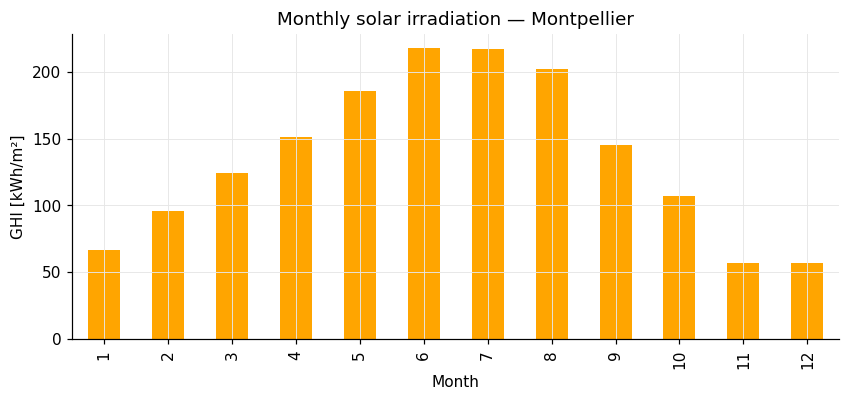

Annual GHI in Montpellier: 1628 kWh/m²


In [5]:
import matplotlib.pyplot as plt

monthly_ghi = weather["ghi"].groupby(weather.index.month).sum() / 1000

monthly_ghi.plot(kind="bar", color="orange")
plt.xlabel("Month")
plt.ylabel("GHI [kWh/m²]")
plt.title("Monthly solar irradiation — Montpellier")
plt.show()

annual_ghi = monthly_ghi.sum()
print(f"Annual GHI in Montpellier: {annual_ghi:.0f} kWh/m²")

**Result:** annual GHI = **1,628 kWh/m²**.
June–July give about 218 kWh/m² each, while Nov–Dec give about 57, roughly 4× less.
Production will therefore be strongly seasonal, peaking in summer.

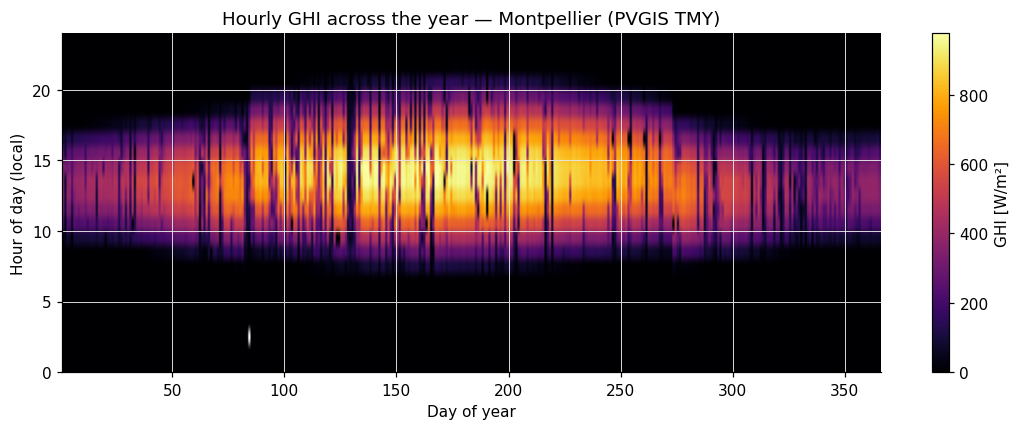

In [6]:
# Day-of-year × hour heatmap: where the solar energy sits in the year
weather = weather.tz_convert("Europe/Paris")
ghi_map = weather.pivot_table(
    index=weather.index.hour,         # rows = hour of day (0–23)
    columns=weather.index.dayofyear,  # columns = day of year (1–365)
    values="ghi"
)

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(ghi_map, aspect="auto", origin="lower",
               cmap="inferno", extent=[1, 366, 0, 24])
fig.colorbar(im, ax=ax, label="GHI [W/m²]")

ax.set_xlabel("Day of year")
ax.set_ylabel("Hour of day (local)")
ax.set_title("Hourly GHI across the year — Montpellier (PVGIS TMY)")
plt.show()

**Interpretation:** the bright band is the daylight period. It is wide in summer (long days) and narrow in winter.
The vertical dark streaks are cloudy days. This is real data, not a clear-sky model.
The band moves up by 1 h around day 87 and back around day 300: this is the summer-time clock change (local time).
The small white mark near day 85 at 2 am is the hour that does not exist when the clocks go forward (no data).

## 2. String sizing against the inverter datasheet
Design: **26 modules per string, 22 strings per inverter, 16 inverters**.
Modules: JA Solar JAM72S30-550/MR/1500V. Inverter: Sungrow SG250HX-20.

Checks:
- **Cold Voc** (open-circuit voltage at the lowest design temperature) must stay ≤ 1,500 V, including the +3 % datasheet tolerance.
- **Hot Vmp** (voltage at maximum power with hot cells) must stay ≥ 500 V, the lower limit of the MPPT (maximum power point tracking) range.
- **Current per MPPT input** must stay below the inverter limits.

In [7]:
# ── A: datasheet values ──────────────────────────────────────────
module = dict(pmax=550, voc=49.90, vmp=41.96, isc=14.00, imp=13.11,
              beta_voc=-0.275/100, voc_tol=0.03)                 # JA Solar JAM72S30-550/MR
inverter = dict(pac=250_000, vdc_max=1500, mppt_min=500, mppt_max=1500,
                n_mppt=6, inputs_per_mppt=4, imax_mppt=65, isc_max_mppt=100)  # Sungrow SG250HX-20
design = dict(mods_per_string=26, strings_per_inv=22, n_inv=16)

# ── B: temperature correction ────────────────────────────────────
T_MIN, T_HOT = -10, 70      # °C: design low temperature and hot cell temperature
voc_cold = module["voc"] * (1 + module["beta_voc"] * (T_MIN - 25))
vmp_hot  = module["vmp"] * (1 + module["beta_voc"] * (T_HOT - 25))

# ── C: design checks against the inverter limits ─────────────────
n   = design["mods_per_string"]
spm = int(np.ceil(design["strings_per_inv"] / inverter["n_mppt"]))   # strings per MPPT = 4

checks = pd.DataFrame([
    ["String Voc at −10 °C (+3 % tol.)", n*voc_cold*(1+module["voc_tol"]), "≤", inverter["vdc_max"],      "V"],
    ["String Vmp at 70 °C cell",         n*vmp_hot,                        "≥", inverter["mppt_min"],     "V"],
    ["String Vmp at STC",                n*module["vmp"],                  "≤", inverter["mppt_max"],     "V"],
    ["Imp per MPPT (4 strings)",         spm*module["imp"],                "≤", inverter["imax_mppt"],    "A"],
    ["Isc per MPPT (4 strings)",         spm*module["isc"],                "≤", inverter["isc_max_mppt"], "A"],
    ["Strings per inverter",             design["strings_per_inv"],        "≤", inverter["n_mppt"]*inverter["inputs_per_mppt"], "—"],
], columns=["Check", "Value", "Rule", "Limit", "Unit"])

ok = np.where(checks.Rule == "≤", checks.Value <= checks.Limit, checks.Value >= checks.Limit)
checks["Margin %"] = (100 * abs(checks.Limit - checks.Value) / checks.Limit).round(1)
checks["Result"]   = np.where(ok, "PASS", "FAIL")
checks["Value"]    = checks["Value"].round(1)

# ── D: allowed string length and plant size ──────────────────────
max_mods  = int(inverter["vdc_max"] // (voc_cold * (1 + module["voc_tol"])))
min_mods  = int(np.ceil(inverter["mppt_min"] / vmp_hot))
n_modules = n * design["strings_per_inv"] * design["n_inv"]
P_DC = n_modules * module["pmax"] / 1000      # kWp
P_AC = design["n_inv"] * inverter["pac"] / 1000   # kW

summary = pd.DataFrame([
    ["Module Voc at design low temperature", f"{T_MIN} °C",        round(voc_cold, 2),   "V"],
    ["Module Vmp at hot cell temperature",   f"{T_HOT} °C",        round(vmp_hot, 2),    "V"],
    ["Minimum modules per string",           "Vmp hot ≥ 500 V",    min_mods,             "modules"],
    ["Maximum modules per string",           "Voc cold ≤ 1500 V",  max_mods,             "modules"],
    ["Design modules per string",            "chosen",             n,                    "modules"],
    ["Total modules",                        "26 × 22 × 16",       n_modules,            "modules"],
    ["DC power",                             "STC",                round(P_DC, 1),       "kWp"],
    ["AC power",                             "16 inverters",       round(P_AC, 0),       "kW"],
    ["DC/AC ratio",                          "DC ÷ AC",            round(P_DC/P_AC, 2),  "—"],
], columns=["Parameter", "Condition", "Value", "Unit"])

# ── Show both tables ─────────────────────────────────────────────
summary["Value"] = summary["Value"].map(lambda v: f"{v:g}")   # 14, 9152, 54.7, 1.26
display(checks.set_index("Check"))
display(summary.set_index("Parameter"))

,Value,Rule,Limit,Unit,Margin %,Result
Check,,,,,,
String Voc at −10 °C (+3 % tol.),1464.9,≤,1500,V,2.3,PASS
String Vmp at 70 °C cell,956.0,≥,500,V,91.2,PASS
String Vmp at STC,1091.0,≤,1500,V,27.3,PASS
Imp per MPPT (4 strings),52.4,≤,65,A,19.3,PASS
Isc per MPPT (4 strings),56.0,≤,100,A,44.0,PASS
Strings per inverter,22.0,≤,24,—,8.3,PASS


,Condition,Value,Unit
Parameter,,,
Module Voc at design low temperature,-10 °C,54.7,V
Module Vmp at hot cell temperature,70 °C,36.77,V
Minimum modules per string,Vmp hot ≥ 500 V,14,modules
Maximum modules per string,Voc cold ≤ 1500 V,26,modules
Design modules per string,chosen,26,modules
Total modules,26 × 22 × 16,9152,modules
DC power,STC,5033.6,kWp
AC power,16 inverters,4000,kW
DC/AC ratio,DC ÷ AC,1.26,—


**Results**
- All **6 checks pass**.
- The **binding constraint is cold Voc**: 1,464.9 V against a 1,500 V limit, only **2.3 % margin**. A 27th module would push the string above 1,500 V, so **26 modules is the maximum string length**.
- Hot Vmp (956 V) is far above the 500 V MPPT minimum. Strings could be as short as 14 modules, so heat is not a risk here.
- Currents per MPPT input have 19–44 % margin, and 22 of the 24 inputs are used.
- Plant: **9,152 modules, 5,033.6 kWp DC, 4,000 kW AC, DC/AC = 1.26**.

**Engineering notes**
- −10 °C is a **design value** for Montpellier, not taken from the TMY. The TMY minimum is −5 °C, but a typical year does not contain record cold.
- Vmp is corrected with β_Voc, which is a common approximation. A datasheet β_Vmp would be slightly more precise.
- A DC/AC ratio of 1.26 means the inverters will **clip** at midday peaks. Section 4 checks how much energy that costs.

Why does cold set the maximum string length and heat set the minimum?

A PV module’s voltage goes up when it’s cold and down when it’s hot, by about −0.3 % per °C.
Modules in a string are in series, so their voltages add up.

On a cold, clear morning, the inverter hasn’t started yet and the string is at open circuit. Voc is at its highest, so the string must stay below the inverter’s maximum DC voltage (1,500 V). If it goes over, the inverter can be damaged and the installation breaks the standard. That limits how many modules you can put in series: the maximum.
On a hot afternoon, cells reach about 70 °C and Vmp drops. If the string voltage falls below the MPPT minimum (500 V), the inverter can’t track the maximum power point and energy is lost. That sets how few modules you can use: the minimum.”

With my numbers:

In my design, 26 modules give 1,465 V at −10 °C, against a 1,500 V limit with only 2.3 % margin. A 27th module would exceed it, so 26 is the maximum. The minimum is 14 modules, so hot conditions are not the limiting case in Montpellier.”



Why use the design minimum temperature with no irradiance? At dawn there is light but the cells are still at air temperature, so cell temperature = ambient. This is the worst case for voltage.
Why add the +3 % tolerance? Real modules can have a Voc up to 3 % higher than the datasheet value. The standard practice is to design with that margin.
What would change in Chambéry? The record low is colder (about −15 °C or below), so Voc is higher and the maximum string length goes down.

## 3. Plane-of-array irradiance and cell temperature
Modules are tilted, so they receive more energy than a horizontal surface. Steps:
1. **Sun position** for every hour (zenith and azimuth angles).
2. **Transposition:** convert GHI/DNI/DHI into the irradiance on the module plane (**POA = plane of array**). Plane: **35° tilt, 180° azimuth (south)**, Perez sky model, ground albedo 0.2.
3. **Cell temperature** with the SAPM model (Sandia Array Performance Model). Hot cells produce less power.

In [8]:
#A: site and sun position

location = pvlib.location.Location(latitude=43.611, longitude=3.877,
                                   altitude=27, tz="UTC", name="Montpellier")
TILT, AZIMUTH, ALBEDO = 35, 180, 0.20

solpos = location.get_solarposition(weather.index)
solpos[["apparent_zenith", "azimuth"]].iloc[8:16]     # one morning, hour by hour

#B: transposition to the module plane

dni_extra = pvlib.irradiance.get_extra_radiation(weather.index)
airmass   = pvlib.atmosphere.get_relative_airmass(solpos["apparent_zenith"])

poa = pvlib.irradiance.get_total_irradiance(
    surface_tilt=TILT, surface_azimuth=AZIMUTH,
    solar_zenith=solpos["apparent_zenith"], solar_azimuth=solpos["azimuth"],
    dni=weather["dni"], ghi=weather["ghi"], dhi=weather["dhi"],
    dni_extra=dni_extra, airmass=airmass, albedo=ALBEDO, model="perez")

poa.describe().round(1)

#C: cell temperature and results table

params = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["open_rack_glass_polymer"]
t_cell = pvlib.temperature.sapm_cell(poa["poa_global"], weather["temp_air"],
                                     weather["wind_speed"], **params)

H_poa = poa["poa_global"].sum() / 1000
res3 = pd.DataFrame([
    ["Annual GHI (horizontal)",        round(annual_ghi),        "kWh/m²"],
    ["Annual POA (35° south)",         round(H_poa),             "kWh/m²"],
    ["Gain from tilting",              round(100*(H_poa/annual_ghi - 1), 1), "%"],
    ["Max cell temperature",           round(t_cell.max(), 1),   "°C"],
    ["Max air temperature",            round(weather["temp_air"].max(), 1), "°C"],
], columns=["Result", "Value", "Unit"])
res3.set_index("Result")

,Value,Unit
Result,,
Annual GHI (horizontal),1628.0,kWh/m²
Annual POA (35° south),2007.0,kWh/m²
Gain from tilting,23.3,%
Max cell temperature,66.4,°C
Max air temperature,40.6,°C


**Results**
- Tilting the modules to 35° south raises annual irradiation from **1,628 to 2,007 kWh/m²**, a **+23.3 % gain**.
- Maximum cell temperature is **66.4 °C**, compared with 40.6 °C maximum air temperature, so cells run up to about 26 °C hotter than the air.
- 66.4 °C is below the 70 °C used for string sizing in Section 2, so that design assumption was conservative.

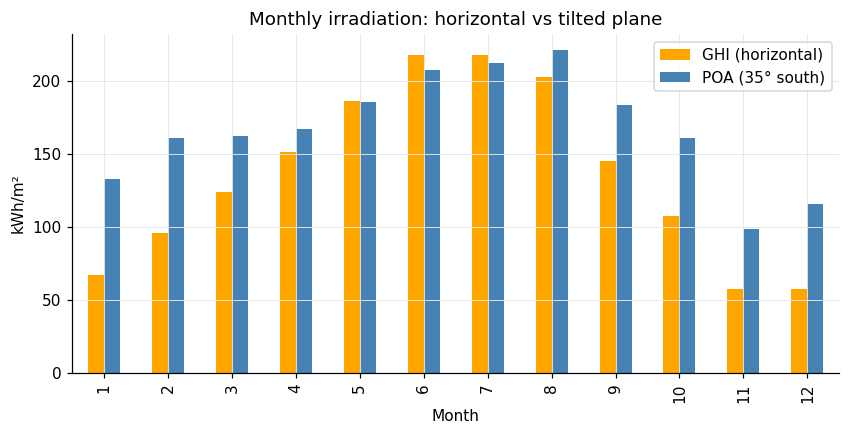

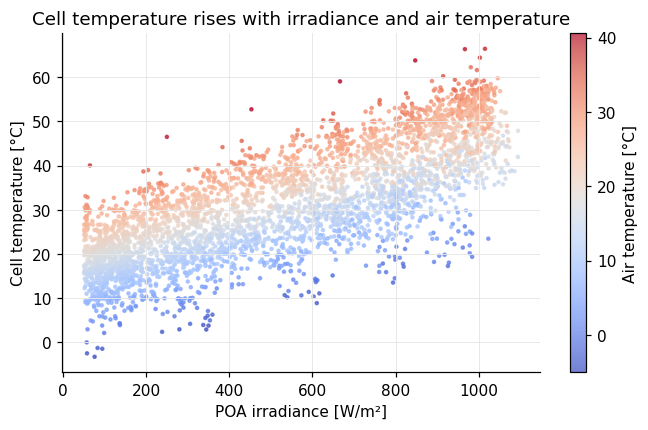

In [9]:
#D: charts
# Monthly GHI vs POA
monthly = pd.DataFrame({
    "GHI (horizontal)": weather["ghi"].groupby(weather.index.month).sum() / 1000,
    "POA (35° south)":  poa["poa_global"].groupby(poa.index.month).sum() / 1000,
})
monthly.plot(kind="bar", color=["orange", "steelblue"], figsize=(9, 4))
plt.xlabel("Month"); plt.ylabel("kWh/m²"); plt.title("Monthly irradiation: horizontal vs tilted plane")
plt.show()

# Cell temperature vs irradiance (daylight hours)
day = poa["poa_global"] > 50
plt.figure(figsize=(7, 4))
sc = plt.scatter(poa["poa_global"][day], t_cell[day], c=weather["temp_air"][day],
                 s=4, cmap="coolwarm", alpha=0.7)
plt.colorbar(sc, label="Air temperature [°C]")
plt.xlabel("POA irradiance [W/m²]"); plt.ylabel("Cell temperature [°C]")
plt.title("Cell temperature rises with irradiance and air temperature")
plt.show()

Interpretation:the tilt helps most in **winter**: January POA is about 133 vs 67 kWh/m² horizontal (≈2×), and December about 116 vs 57.
In **June–July** the tilted plane receives slightly *less* than horizontal (≈207–212 vs 218). The summer sun is high, so a 35° plane faces "below" it.
35° is a compromise that flattens the seasonal profile and maximises the **annual** total, not the summer peak.

Interpretation: cell temperature rises roughly linearly with irradiance (about +25–30 °C at 1,000 W/m²) and moves up or down with air temperature (the colour layers).
The hottest cells (≈60–66 °C) occur on hot, sunny summer afternoons. Isolated points above the main cloud are hours with low wind (less cooling).
With γ ≈ −0.35 %/°C, a cell at 65 °C loses about **14 % of its power** compared with STC (25 °C). Section 4 includes this loss.

SUMMARY 
 Using hourly sun positions and the Perez model, the PVGIS weather was transposed onto a 35° south-facing plane. This gives 2,007 kWh/m²/year (+23 % vs horizontal), with the largest gains in winter. SAPM cell temperatures peak at 66 °C, which confirms the 70 °C hot-case assumption from Section 2 and quantifies the thermal loss used in the energy simulation.

 Why not tilt the modules to the latitude (43.6°)? A tilt close to the latitude maximises the annual total for a fixed plane. Utility plants often use a lower tilt, about 25–35°, to reduce row shading and wind load, and to fit more rows on the land.
Why is POA lower than GHI in summer? Two reasons: the sun is high, so its angle to the tilted plane is worse; and a tilted plane sees less of the sky, so it receives less diffuse light.

## 4. Energy simulation: DC, losses, inverter and clipping
- **DC power (PVWatts model):** `P_dc = P_dc0 × (POA/1000) × [1 + γ (T_cell − 25)]`, with γ = −0.35 %/°C (datasheet).
- **System losses:** soiling, wiring, mismatch, availability, etc., combined with `pvwatts_losses` (≈14 %, the same assumption as my PVGIS run).
- **Inverter:** constant European efficiency of 98.8 %. AC output is capped at **4,000 kW**. Any energy above the cap is lost: this is **clipping**.
- **Performance Ratio (PR)** = specific yield ÷ in-plane irradiation. It shows how much of the available sunlight becomes AC energy, after all losses.

In [10]:
#A: hourly simulation and annual results

GAMMA  = -0.35 / 100                       # power temperature coefficient (datasheet)
ETA    = 0.988                             # inverter European efficiency (datasheet)
LOSSES = pvlib.pvsystem.pvwatts_losses()   # % system losses (default ≈14.08)
pdc0, pac0 = P_DC * 1000, P_AC * 1000      # kW → W

def simulate(pdc_nameplate):
    """Hourly AC power with and without the inverter limit, for a DC size in W."""
    dc = pvlib.pvsystem.pvwatts_dc(poa["poa_global"], t_cell, pdc_nameplate, GAMMA)
    dc = (dc * (1 - LOSSES / 100)).clip(lower=0)
    ac_free = dc * ETA                    # AC if the inverter had no limit
    ac = ac_free.clip(upper=pac0)         # AC actually delivered
    return dc, ac_free, ac

p_dc, p_ac_free, p_ac = simulate(pdc0)

E_ac   = p_ac.sum() / 1e6                  # Wh → MWh (hourly data)
E_clip = (p_ac_free - p_ac).sum() / 1e6
Y_spec = E_ac * 1000 / P_DC                # kWh/kWp
PR     = Y_spec / H_poa

res4 = pd.DataFrame([
    ["DC capacity",          P_DC,               "kWp"],
    ["AC capacity",          P_AC,               "kW"],
    ["In-plane irradiation", H_poa,              "kWh/m²"],
    ["System losses",        LOSSES,             "%"],
    ["Annual AC energy",     E_ac,               "MWh"],
    ["Specific yield",       Y_spec,             "kWh/kWp"],
    ["Performance ratio",    100 * PR,           "%"],
    ["Clipping loss",        E_clip,             "MWh"],
    ["Clipping loss",        100 * E_clip/E_ac,  "% of AC"],
    ["PVGIS report result",  7532.57,            "MWh"],
], columns=["Result", "Value", "Unit"])
res4["Value"] = res4["Value"].round(1)
res4.set_index("Result")

,Value,Unit
Result,,
DC capacity,5033.6,kWp
AC capacity,4000.0,kW
In-plane irradiation,2007.2,kWh/m²
System losses,14.1,%
Annual AC energy,8214.1,MWh
Specific yield,1631.8,kWh/kWp
Performance ratio,81.3,%
Clipping loss,15.9,MWh
Clipping loss,0.2,% of AC


**Results**
- Annual AC energy: **8,214 MWh**, a specific yield of **1,632 kWh/kWp**, and a **PR of about 81 %**.
- Clipping loss: about **16 MWh/year (≈0.2 %)**. With a DC/AC ratio of 1.26 and 14 % system losses, the DC power rarely exceeds the 4,000 kW inverter limit.

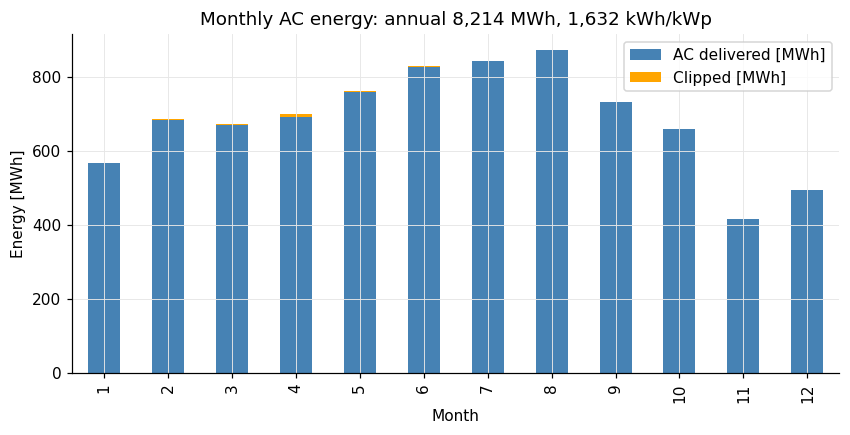

Month,1,2,3,4,5,6,7,8,9,10,11,12
AC delivered [MWh],565.8,684.2,670.3,692.5,758.6,828.0,843.1,872.5,731.6,657.7,416.2,493.6
Clipped [MWh],0.0,2.5,2.1,6.7,3.8,0.3,0.2,0.0,0.3,0.0,0.0,0.0


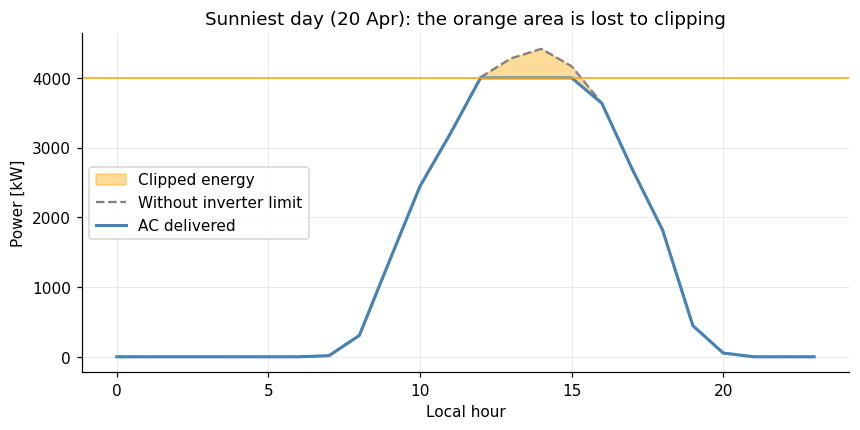

In [11]:
#B: monthly energy (stacked bars)

monthly_e = pd.DataFrame({
    "AC delivered [MWh]": p_ac.groupby(p_ac.index.month).sum() / 1e6,
    "Clipped [MWh]":      (p_ac_free - p_ac).groupby(p_ac.index.month).sum() / 1e6,
})
monthly_e.index.name = "Month"
monthly_e.plot(kind="bar", stacked=True, color=["steelblue", "orange"], figsize=(9, 4))
plt.xlabel("Month"); plt.ylabel("Energy [MWh]")
plt.title(f"Monthly AC energy: annual {E_ac:,.0f} MWh, {Y_spec:,.0f} kWh/kWp")
plt.show()
display(monthly_e.round(1).T)

#C: zoom on the sunniest day

local_free = p_ac_free.tz_convert("Europe/Paris")
local_ac   = p_ac.tz_convert("Europe/Paris")
peak_day   = local_free.resample("D").max().idxmax().date()   # day with the highest unclipped power

free = local_free.loc[str(peak_day)] / 1e3     # kW
real = local_ac.loc[str(peak_day)] / 1e3


plt.figure(figsize=(9, 4))
plt.fill_between(free.index.hour, real, free, color="orange", alpha=0.4, label="Clipped energy")
plt.plot(free.index.hour, free, "--", color="grey", label="Without inverter limit")
plt.plot(real.index.hour, real, color="steelblue", lw=2, label="AC delivered")
plt.axhline(P_AC, color="orange", lw=1)
plt.xlabel("Local hour"); plt.ylabel("Power [kW]")
plt.title(f"Sunniest day ({peak_day:%d %b}): the orange area is lost to clipping")
plt.legend(); plt.show()

**Interpretation:** production follows the in-plane irradiation. August is the highest month (≈873 MWh) and November the lowest (≈416 MWh).
Clipping appears mainly in **March–May**. Spring combines high in-plane irradiance (the tilt suits the mid-height sun) with **cool cells**, which produce more power, so the DC peak is highest then, not in summer.
In summer, hot cells (up to 66 °C) lower the DC peak, so there is almost no clipping.

**Interpretation:** on 20 April the unclipped output reaches about 4,400 kW. Between about 12:00 and 15:00 the inverter caps it at 4,000 kW, and the orange area is lost.
This is the trade-off of oversizing the DC side: a small loss on a few peak hours, in exchange for more energy in the morning, the evening and in winter (Section 5 quantifies this).

**Comparison with PVGIS:** my PVGIS report gave 7,532.57 MWh. This model gives 8,214 MWh (+9 %). Main reasons:
1. **Optical losses not modelled here:** PVWatts as used here ignores reflection at low sun angles (IAM, incidence angle modifier) and spectral effects. PVGIS includes them (≈3–5 %).
2. **Different capacity:** PVGIS used 4,990 kWp, while this model uses 5,033.6 kWp (+0.9 %).
3. **Weather and temperature models:** this model uses one TMY year with SAPM cell temperature, while PVGIS uses its own multi-year average and thermal model.
→ A gap of 5–10 % between two simulation tools is normal at the pre-design stage. The more conservative PVGIS value is the one to use for financial estimates.

**Section 4 summary:** An hourly PVWatts + inverter model gives **8,214 MWh/year (1,632 kWh/kWp, PR ≈ 81 %)** for the 5.03 MWp / 4 MW plant. Inverter clipping is only ≈0.2 %, mostly on cool, clear spring days, which confirms that a DC/AC ratio of 1.26 is well chosen. The result is 9 % above PVGIS, mainly because optical losses are not modelled.

What is a good PR? For utility-scale plants, about 75–85 %. Above 85 % is suspicious: losses are probably missing from the model.
Why accept clipping? Inverters are expensive. A slightly smaller inverter loses about 0.2 % of energy but saves capital (CAPEX) and makes better use of the grid connection all year.

